# 02 · Delivery lateness

**Question:** How often are delivered orders late, by how much, and does the
late rate vary over time and by customer state?

"Late" = delivered on a later date than the estimated date (see
`sql/01_order_delivery.sql`). Only delivered orders are included.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

# Notebooks run from notebooks/, so add src/ to the import path.
sys.path.insert(0, str(Path.cwd().parent / "src"))
from db import query

sns.set_theme(style="whitegrid")

## 1. Late rate

**Question:** What share of delivered orders arrived after the estimated date?

In [2]:
query("""
    SELECT is_late,
           COUNT(*)                                        AS orders,
           ROUND(COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (), 4) AS share
    FROM order_delivery
    WHERE is_delivered
    GROUP BY is_late
""")

,is_late,orders,share
0,False,89936,0.9323
1,True,6534,0.0677


**Observations:**

- Of 96,470 delivered orders, **6.8%** (~6,500) arrived after the estimated
  date; 93.2% were on time or early.
- Late orders are a small minority (~1 in 15). For the model, accuracy will
  be misleading: always predicting "on time" would already be 93% accurate.

## 2. How early or late

**Question:** How are `days_late` distributed? Negative = early, positive = late.
The plot is clipped to ±60 days so the bulk is readable; the table shows the full range.

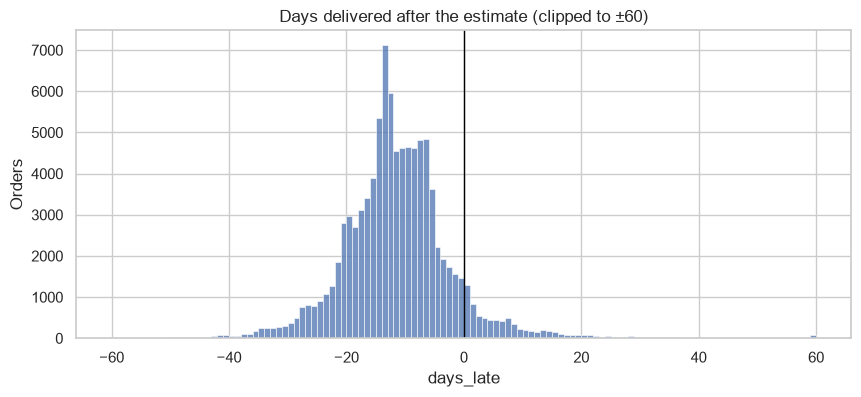

count    96470.000000
mean       -11.875889
std         10.182105
min       -147.000000
5%         -26.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
95%          3.000000
max        188.000000
Name: days_late, dtype: float64

In [3]:
days = query("SELECT days_late FROM order_delivery WHERE is_delivered")

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(days["days_late"].clip(-60, 60), binwidth=1, ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Days delivered after the estimate (clipped to ±60)", xlabel="days_late", ylabel="Orders")
plt.show()

days["days_late"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

In [4]:
# Among late orders only: how late?
days.loc[days["days_late"] > 0, "days_late"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])

count    6534.000000
mean       10.620141
std        14.644955
min         1.000000
25%         3.000000
50%         7.000000
75%        13.000000
90%        22.000000
95%        31.000000
max       188.000000
Name: days_late, dtype: float64

**Observations:**

- Most orders arrive **early**: a typical (median) order arrives **12 days
  before** the estimated date.
- This suggests Olist sets **generous estimates** ("under-promise,
  over-deliver"), likely as a buffer for variable delivery times and to keep
  customers satisfied.
- Late orders are typically **7 days late** (median); mean 10.6 days,
  pulled up by a long tail. 95% of late orders are within 31 days.
- The spike at +60 is **84 orders that were 60+ days late** (max 188),
  stacked there by the ±60 clipping. They are real extreme delays, kept.

## 3. Late rate over time

**Question:** Does the late rate change by purchase month? Months with few
orders are noisy; check the `orders` column before reading the line.

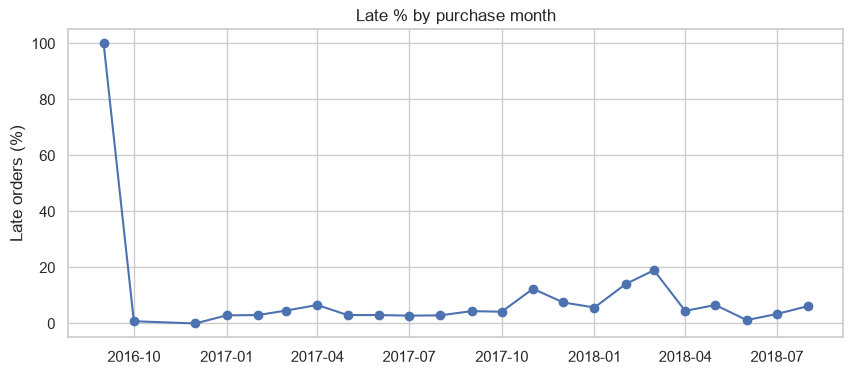

,month,orders,late_orders,late_pct
0,2016-09-01,1,1,100.0
1,2016-10-01,265,2,0.8
2,2016-12-01,1,0,0.0
3,2017-01-01,750,22,2.9
4,2017-02-01,1653,49,3.0
5,2017-03-01,2546,116,4.6
6,2017-04-01,2303,151,6.6
7,2017-05-01,3545,106,3.0
8,2017-06-01,3135,95,3.0
9,2017-07-01,3872,108,2.8


In [6]:
by_month = query("""
    SELECT date_trunc('month', order_purchase_timestamp)::date AS month,
           COUNT(*)                                            AS orders,
           COUNT(*) FILTER (WHERE is_late)                     AS late_orders,
           ROUND(100 * AVG(is_late::int), 1)                   AS late_pct
    FROM order_delivery
    WHERE is_delivered
    GROUP BY 1
    ORDER BY 1
""")

ax = by_month.plot(x="month", y="late_pct", marker="o", legend=False, figsize=(10, 4))
ax.set(title="Late % by purchase month", xlabel="", ylabel="Late orders (%)")
plt.show()
by_month

**Observations:**

- Normal months: **~3%** late.
- Peaks: **Nov 2017 (12.4%)** (Black Friday), **Feb 2018 (14.1%)**, **Mar 2018 (19.0%)**.
- These 3 months produce **48%** of all late orders. Without them, late % is **4.5%**, not 6.8%.
- 2016 months are too small to trust → use Jan 2017 – Aug 2018.

## 4. Late rate by customer state

**Question:** Does the late rate differ by the customer's state? States with
few orders are noisy, so `orders` is shown next to the rate.

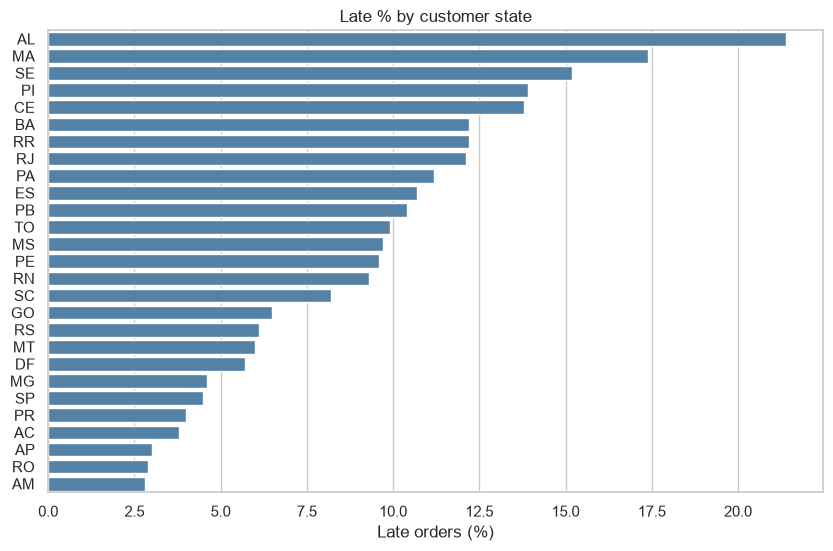

,customer_state,orders,late_orders,late_pct
0,AL,397,85,21.4
1,MA,717,125,17.4
2,SE,335,51,15.2
3,PI,476,66,13.9
4,CE,1279,176,13.8
5,BA,3256,396,12.2
6,RR,41,5,12.2
7,RJ,12350,1495,12.1
8,PA,946,106,11.2
9,ES,1995,214,10.7


In [7]:
by_state = query("""
    SELECT customer_state,
           COUNT(*)                            AS orders,
           COUNT(*) FILTER (WHERE is_late)     AS late_orders,
           ROUND(100 * AVG(is_late::int), 1)   AS late_pct
    FROM order_delivery
    WHERE is_delivered
    GROUP BY customer_state
    ORDER BY late_pct DESC
""")

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=by_state, y="customer_state", x="late_pct", color="steelblue", ax=ax)
ax.set(title="Late % by customer state", xlabel="Late orders (%)", ylabel="")
plt.show()
by_state

**Observations:**

- Late % varies a lot by state: from **2.8% (AM)** to **21.4% (AL)**.
- 71% of items are sold from **SP**. States near SP are low
  (SP 4.5%, PR 4.0%, MG 4.6%); far Northeast states are high
  (AL 21.4%, MA 17.4%, SE 15.2%) → **distance likely matters**.
- But not everything fits: **RJ** (close to SP) is high at **12.1%**, and far
  North states (AM, RO, AP) are among the lowest (~3%). Lateness is measured
  against the promise, which may already be longer for far states.
- Small states (RR 41, AP 67, AC 80 orders) are too small to trust.

## Decisions from this notebook

1. **Late rate:** 6.8% of delivered orders. Classes are imbalanced, so
   accuracy is the wrong metric for the model.
2. **Most orders arrive ~12 days early**, so Olist's estimates are generous.
   Phase 2 should check whether reviews react to the promise, not only speed.
3. **Lateness comes in bursts** (Nov 2017, Feb–Mar 2018 hold 48% of late
   orders). Use a **time-based** train/test split and check which periods
   it covers.
4. **Feature ideas for the model** (all known at purchase):
   seller–customer **distance**, customer state, **promised delivery days**,
   and **purchase month**.
5. Use purchases from **Jan 2017 – Aug 2018** (as in notebook 01).